# Execute the code below

In [39]:
import pandas as pd
import numpy as np
link = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather2019.csv"
df_weather = pd.read_csv(link)

In [40]:
#columns = colonnes
#index = lignes
#values = valeurs
#aggfunc = fonction d'agrégation

# You have now a DataFrame with lots of weather data

In [41]:
df_weather.head()

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,WINDTEMP_MAX_C,WEATHER_CODE_MORNING,WEATHER_CODE_NOON,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,MONTH,DAY
0,2019-01-01,9,4,10,4,7,8,0.2,94,9.0,...,3,116,143,176,0,1,5.1,very bad,1,1
1,2019-01-02,8,5,18,7,7,5,0.0,90,9.0,...,3,119,116,116,0,1,8.7,very bad,1,2
2,2019-01-03,6,0,18,0,4,3,0.0,88,10.0,...,-4,116,116,116,0,1,8.7,very bad,1,3
3,2019-01-04,5,-1,15,-1,4,3,0.0,91,10.0,...,-4,116,116,122,0,1,5.1,very bad,1,4
4,2019-01-05,6,-1,8,-1,4,3,0.0,91,8.0,...,-2,143,116,116,0,1,8.7,very bad,1,5


In [42]:
df_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   DATE                    365 non-null    object 
 1   MAX_TEMPERATURE_C       365 non-null    int64  
 2   MIN_TEMPERATURE_C       365 non-null    int64  
 3   WINDSPEED_MAX_KMH       365 non-null    int64  
 4   TEMPERATURE_MORNING_C   365 non-null    int64  
 5   TEMPERATURE_NOON_C      365 non-null    int64  
 6   TEMPERATURE_EVENING_C   365 non-null    int64  
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64  
 9   VISIBILITY_AVG_KM       365 non-null    float64
 10  PRESSURE_MAX_MB         365 non-null    int64  
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64
 12  HEATINDEX_MAX_C         365 non-null    int64  
 13  DEWPOINT_MAX_C          365 non-null    int64  
 14  WINDTEMP_MAX_C          365 non-null    in

# PIVOT TABLE

## It's like in Excel, but with Pandas

There are 2 syntaxes, choose your preferred :
- As a method : YOUR_DATAFRAME.pivot_table()
- As a function : pd.crosstab()

In [43]:
# Example
df_weather.pivot_table(values = 'MAX_TEMPERATURE_C', index = 'MONTH', aggfunc = 'mean')

,MAX_TEMPERATURE_C
MONTH,
1,8.161290
2,12.750000
3,13.064516
4,14.900000
5,16.870968
6,22.166667
7,26.806452
8,25.290323
9,22.533333


## Create a Pivot table with :
- Months on rows
- the maximum of Max Temperature on values
- Opinion on columns

In [44]:
# Hop !

df_weather.pivot_table(columns = "OPINION", values = "MAX_TEMPERATURE_C", index = "MONTH", aggfunc = "max")

OPINION,bad,good,not good not bad,very bad,very good
MONTH,,,,,
1,11.0,NaN,NaN,10.0,NaN
2,13.0,20.0,17.0,12.0,NaN
3,14.0,19.0,17.0,12.0,NaN
4,18.0,24.0,19.0,14.0,NaN
5,19.0,25.0,20.0,15.0,NaN
6,23.0,32.0,34.0,15.0,29.0
7,31.0,33.0,39.0,22.0,33.0
8,24.0,33.0,30.0,NaN,29.0
9,21.0,31.0,20.0,20.0,NaN


## Pivot table with :
- Days on rows
- Precipitation on values
- Months on columns


In [45]:
# Hop !
from datetime import datetime
df_weather["DATE"] = pd.to_datetime(df_weather["DATE"])
df_weather["Day"] = df_weather["DATE"].dt.day_name(locale="fr_FR")
df_weather.pivot_table(columns = "MONTH", values = "PRECIP_TOTAL_DAY_MM", index = "Day")

MONTH,1,2,3,4,5,6,7,8,9,10,11,12
Day,,,,,,,,,,,,
Dimanche,1.550,7.275,3.400,3.375,1.100,1.000,0.425,2.750,2.440,2.225,8.700,3.420
Jeudi,1.600,1.225,1.000,1.400,2.460,1.250,0.200,0.140,0.125,4.100,10.125,12.350
Lundi,0.675,4.900,3.100,3.160,2.100,4.325,0.440,0.750,2.120,2.450,4.150,5.140
Mardi,5.060,0.825,1.575,3.520,0.800,2.650,1.220,1.150,7.925,2.920,4.875,4.060
Mercredi,0.920,2.350,12.275,6.500,5.160,1.875,0.060,0.225,0.575,5.800,2.425,1.475
Samedi,1.625,1.825,2.640,2.275,2.275,0.800,3.100,1.500,0.375,2.025,9.780,5.400
Vendredi,1.225,2.225,0.280,3.025,1.680,6.950,4.275,1.100,0.325,1.800,5.720,9.400


## Pivot table with :
- Months on rows
- the sum of Precipitations on values

**Then display it as a column chart.** (optionnal)

In [46]:
# Hop !

df_weather.pivot_table(columns = "MONTH", values = "PRECIP_TOTAL_DAY_MM", index = "Day", aggfunc ="sum")

MONTH,1,2,3,4,5,6,7,8,9,10,11,12
Day,,,,,,,,,,,,
Dimanche,6.2,29.1,17.0,13.5,4.4,5.0,1.7,11.0,12.2,8.9,34.8,17.1
Jeudi,8.0,4.9,4.0,5.6,12.3,5.0,0.8,0.7,0.5,20.5,40.5,49.4
Lundi,2.7,19.6,12.4,15.8,8.4,17.3,2.2,3.0,10.6,9.8,16.6,25.7
Mardi,25.3,3.3,6.3,17.6,3.2,10.6,6.1,4.6,31.7,14.6,19.5,20.3
Mercredi,4.6,9.4,49.1,26.0,25.8,7.5,0.3,0.9,2.3,29.0,9.7,5.9
Samedi,6.5,7.3,13.2,9.1,9.1,4.0,12.4,7.5,1.5,8.1,48.9,21.6
Vendredi,4.9,8.9,1.4,12.1,8.4,27.8,17.1,5.5,1.3,7.2,28.6,37.6


## Pivot table with :
- Months on rows
- the average of Max Temperature on a first column of values
- the average of Sunhours on a second column of values

In [47]:
# Hop !

df_weather.pivot_table(index = "MONTH", values=["MAX_TEMPERATURE_C", "SUNHOUR"],aggfunc="mean")


,MAX_TEMPERATURE_C,SUNHOUR
MONTH,,
1,8.161290,5.709677
2,12.750000,8.346429
3,13.064516,9.077419
4,14.900000,9.533333
5,16.870968,11.809677
6,22.166667,14.170000
7,26.806452,14.141935
8,25.290323,11.135484
9,22.533333,9.683333


# Chart
Using your favorite library (MatPlotLib, Seaborn, Plotly or what you want), draw a chart from the previous pivot table with :
- Temperature in a blue column chart
- Sunhours in a red line plot

Tip : Once your pivot table created, you can help yourself with the `.reset_index()`  method.

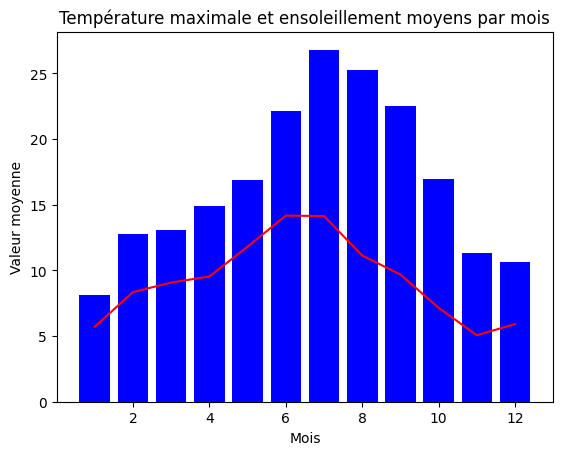

In [48]:
# Your code here
import matplotlib.pyplot as plt

pivot = df_weather.pivot_table(index="MONTH",values=["MAX_TEMPERATURE_C", "SUNHOUR"],aggfunc="mean")

plt.bar(pivot.index, pivot["MAX_TEMPERATURE_C"], color="blue")
plt.plot(pivot.index, pivot["SUNHOUR"], color="red")
plt.title("Température maximale et ensoleillement moyens par mois")
plt.xlabel("Mois")
plt.ylabel("Valeur moyenne")

plt.show()

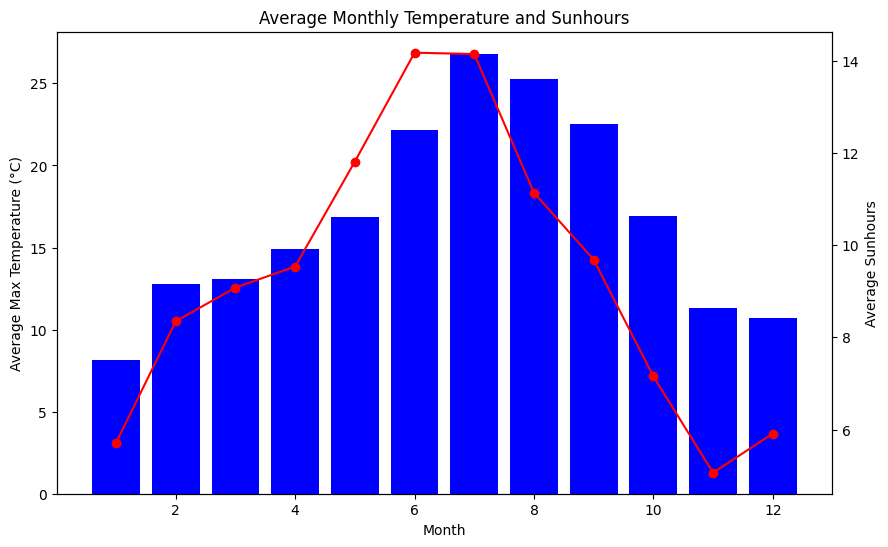

In [50]:
# ou alors

# Création de la figure est du 1èr axe(ax1)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Température en blue en bar
ax1.bar(
    pivot.index,
    pivot["MAX_TEMPERATURE_C"],
    color="blue"
)
ax1.set_xlabel("Month")
ax1.set_ylabel("Average Max Temperature (°C)")

# Axe pour SUNHOUR
ax2 = ax1.twinx()   #ax1 est l'axe principal (ici, pour les barres de température).twinx() crée un second axe vertical (y) qui partage le même axe horizontal (x) que ax1.
                    #Cela permet de tracer deux séries de données avec des échelles différentes sur le même graphique.
ax2.plot(
    pivot.index,
    pivot["SUNHOUR"],
    color="red",
    marker="o"
)
ax2.set_ylabel("Average Sunhours")

# Titre
plt.title("Average Monthly Temperature and Sunhours")

plt.show()